<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/01_data_cleaning_sahil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data cleaning: BoardGameGeek catalogue

Produces `data/bgg_clean.csv`, the table every other notebook in this project starts from.

Steps: load the two raw files, join them on `id`, audit every column (design attribute, community outcome, or identifier), check data quality, apply the cleaning rules, save.

Raw files: `data/ratings.csv` and `data/details.csv`, described in `data/README.md`. Missing values and extreme values are counted here but not removed, so each analysis notebook can make and justify its own choice.

In [1]:
# --- Sahil Dalal: data cleaning, column audit, leakage check, cleaned dataset ---
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13. Every code and markdown cell in this notebook was generated with Claude Code and reviewed, run and edited by Sahil Dalal.
# [AI-assisted] Claude Code (Claude Opus 5.5), 2026-10-25. Revised rule 3 so a missing mechanic or category list gives a missing count instead of 0; reviewed and edited by Sahil Dalal.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the raw files

In [2]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Load both raw files straight from the repository; the same line works in Colab and locally.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
ratings = pd.read_csv(BASE + "ratings.csv")
details = pd.read_csv(BASE + "details.csv")
print("ratings:", ratings.shape, "| details:", details.shape)

ratings: (21831, 10) | details: (21631, 23)


In [3]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# First rows of each file (the long description column is hidden here).
display(ratings.head(3))
details.drop(columns=["description"]).head(3)

,num,id,name,year,rank,average,bayes_average,users_rated,url,thumbnail
0,105,30549,Pandemic,2008,106,7.59,7.487,108975,/boardgame/30549/pandemic,https://cf.geekdo-images.com/S3ybV1LAp-8SnHIXL...
1,189,822,Carcassonne,2000,190,7.42,7.309,108738,/boardgame/822/carcassonne,https://cf.geekdo-images.com/okM0dq_bEXnbyQTOv...
2,428,13,Catan,1995,429,7.14,6.970,108024,/boardgame/13/catan,https://cf.geekdo-images.com/W3Bsga_uLP9kO91gZ...


,num,id,primary,yearpublished,minplayers,maxplayers,playingtime,minplaytime,maxplaytime,minage,...,boardgamefamily,boardgameexpansion,boardgameimplementation,boardgamedesigner,boardgameartist,boardgamepublisher,owned,trading,wanting,wishing
0,0,30549,Pandemic,2008,2,4,45,45,45,8,...,"['Components: Map (Global Scale)', 'Components...",['Pandemic: Gen Con 2016 Promos – Z-Force Team...,"['Pandemic Legacy: Season 0', 'Pandemic Legacy...",['Matt Leacock'],"['Josh Cappel', 'Christian Hanisch', 'Régis Mo...","['Z-Man Games', 'Albi', 'Asmodee', 'Asmodee It...",168364,2508,625,9344
1,1,822,Carcassonne,2000,2,5,45,30,45,7,...,"['Cities: Carcassonne (France)', 'Components: ...","['20 Jahre Darmstadt Spielt', 'Apothecaries (f...","['The Ark of the Covenant', 'Carcassonne für 2...",['Klaus-Jürgen Wrede'],"['Doris Matthäus', 'Anne Pätzke', 'Chris Quill...","['Hans im Glück', '999 Games', 'Albi', 'Bard C...",161299,1716,582,7383
2,2,13,Catan,1995,3,4,120,60,120,10,...,"['Animals: Sheep', 'Components: Hexagonal Tile...","['20 Jahre Darmstadt Spielt', 'Brettspiel Adve...","['Baden-Württemberg Catan', 'Catan Geographies...",['Klaus Teuber'],"['Volkan Baga', 'Tanja Donner', 'Pete Fenlon',...","['KOSMOS', '999 Games', 'Albi', 'Asmodee', 'As...",167733,2018,485,5890


In [4]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Column types and missing values in the details file.
details.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21631 entries, 0 to 21630
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   num                      21631 non-null  int64 
 1   id                       21631 non-null  int64 
 2   primary                  21631 non-null  object
 3   description              21630 non-null  object
 4   yearpublished            21631 non-null  int64 
 5   minplayers               21631 non-null  int64 
 6   maxplayers               21631 non-null  int64 
 7   playingtime              21631 non-null  int64 
 8   minplaytime              21631 non-null  int64 
 9   maxplaytime              21631 non-null  int64 
 10  minage                   21631 non-null  int64 
 11  boardgamecategory        21348 non-null  object
 12  boardgamemechanic        20041 non-null  object
 13  boardgamefamily          17870 non-null  object
 14  boardgameexpansion       5506 non-null

## 2. Join the two files

The data readme says the two files join on `id`. Games that appear in only one file are left out.

In [5]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# How many games are in one file but not the other, then join on id.
print("ids in ratings not in details:", (~ratings["id"].isin(details["id"])).sum())
print("ids in details not in ratings:", (~details["id"].isin(ratings["id"])).sum())
games = ratings.merge(details, on="id", how="inner", suffixes=("_r", "_d"))
print("joined:", games.shape)
agree = (games["year"] == games["yearpublished"]).mean() * 100
print("year (ratings) equals yearpublished (details) in", round(agree, 2), "% of rows")
print("name differs from primary in", (games["name"] != games["primary"]).sum(), "rows")

ids in ratings not in details: 200
ids in details not in ratings: 0
joined: (21631, 32)
year (ratings) equals yearpublished (details) in 99.95 % of rows
name differs from primary in 5 rows


In [6]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Both files carry a row number and a name; keep one of each. Drop the columns that only identify or link the game.
games = games.drop(columns=["num_r", "num_d", "year", "primary", "url", "thumbnail", "description"])
list(games.columns)

['id',
 'name',
 'rank',
 'average',
 'bayes_average',
 'users_rated',
 'yearpublished',
 'minplayers',
 'maxplayers',
 'playingtime',
 'minplaytime',
 'maxplaytime',
 'minage',
 'boardgamecategory',
 'boardgamemechanic',
 'boardgamefamily',
 'boardgameexpansion',
 'boardgameimplementation',
 'boardgamedesigner',
 'boardgameartist',
 'boardgamepublisher',
 'owned',
 'trading',
 'wanting',
 'wishing']

## 3. Column audit

The predictive question predicts a game's `average` rating from its characteristics, for a producer deciding what to make. A column can be an input only if its value is known before the game is released. Ratings, rankings, ownership counts, and the expansions a game later received are all measured after release: they are outcomes, not inputs. Using one of them to predict `average` would be leakage.

In [7]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# One row per column: its role in the project and what happens to it in the clean file.
audit = pd.DataFrame([
    ("id", "identifier", "kept as the key; never a feature"),
    ("name", "identifier", "kept for reading results; never a feature"),
    ("average", "target", "mean user rating, 1 to 10; the predictive target"),
    ("bayes_average", "post-release outcome", "rating shrunk toward the site mean by rating count; derived from average"),
    ("rank", "post-release outcome", "site rank, derived from bayes_average"),
    ("users_rated", "post-release outcome", "number of ratings received"),
    ("owned", "post-release outcome", "members who own the game"),
    ("trading", "post-release outcome", "members offering it for trade"),
    ("wanting", "post-release outcome", "members wanting it"),
    ("wishing", "post-release outcome", "members with it on a wishlist"),
    ("boardgameexpansion", "post-release outcome", "expansions published later; dropped from the clean file"),
    ("boardgameimplementation", "post-release outcome", "re-implementations published later; dropped from the clean file"),
    ("boardgamefamily", "mixed", "mixes pre-release facts with post-release ones; dropped from the clean file"),
    ("yearpublished", "design attribute", "0 means unknown; negative years are games from before year 1"),
    ("minplayers", "design attribute", "0 means unknown"),
    ("maxplayers", "design attribute", "0 means unknown"),
    ("minplaytime", "design attribute", "minutes; 0 means unknown"),
    ("maxplaytime", "design attribute", "minutes; 0 means unknown"),
    ("playingtime", "design attribute", "identical to maxplaytime in every row; dropped"),
    ("minage", "design attribute", "0 means unknown"),
    ("boardgamecategory", "design attribute", "list of categories; kept as pipe-separated text"),
    ("boardgamemechanic", "design attribute", "list of mechanics; kept as pipe-separated text"),
    ("boardgamedesigner", "design attribute", "list; thousands of distinct names"),
    ("boardgameartist", "design attribute", "list; thousands of distinct names"),
    ("boardgamepublisher", "design attribute", "list; thousands of distinct names"),
], columns=["column", "role", "note"])
audit

,column,role,note
0,id,identifier,kept as the key; never a feature
1,name,identifier,kept for reading results; never a feature
2,average,target,"mean user rating, 1 to 10; the predictive target"
3,bayes_average,post-release outcome,rating shrunk toward the site mean by rating c...
4,rank,post-release outcome,"site rank, derived from bayes_average"
5,users_rated,post-release outcome,number of ratings received
6,owned,post-release outcome,members who own the game
7,trading,post-release outcome,members offering it for trade
8,wanting,post-release outcome,members wanting it
9,wishing,post-release outcome,members with it on a wishlist


In [8]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# The columns a predictive model must not use as features, for reference in the other notebooks.
LEAKAGE = ["bayes_average", "rank", "users_rated", "owned", "trading", "wanting", "wishing"]
print("post-release columns kept in the clean file (for description only, never as model inputs):", LEAKAGE)

post-release columns kept in the clean file (for description only, never as model inputs): ['bayes_average', 'rank', 'users_rated', 'owned', 'trading', 'wanting', 'wishing']


## 4. Data quality checks

Each check prints the number of rows affected. The charts show the shape of the key variables before anything is changed.

In [9]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Zero is used as "unknown" in the numeric design columns; years at or below zero are unknown or ancient.
design_num = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "playingtime", "minage"]
(games[design_num] <= 0).sum().rename("rows at 0 or below").to_frame()

,rows at 0 or below
yearpublished,195
minplayers,44
maxplayers,164
minplaytime,642
maxplaytime,774
playingtime,774
minage,1301


In [10]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Games whose minimum player count is above the maximum: every one of them has maxplayers == 0, so this is "maximum unknown", not a contradiction.
bad = games["minplayers"] > games["maxplayers"]
print("minplayers > maxplayers:", bad.sum(), "| of those, maxplayers == 0:", (bad & (games["maxplayers"] == 0)).sum())

minplayers > maxplayers: 129 | of those, maxplayers == 0: 129


In [11]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# playingtime carries no information beyond maxplaytime.
same = (games["playingtime"] == games["maxplaytime"]).mean() * 100
print("playingtime equals maxplaytime in", round(same, 1), "% of rows")

playingtime equals maxplaytime in 100.0 % of rows


In [12]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Spread of the numeric columns, with the tails that matter.
cols = ["average", "users_rated", "yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage"]
games[cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
average,21631.0,6.42,0.93,1.04,4.02,4.84,5.83,6.45,7.04,7.88,8.47,9.57
users_rated,21631.0,874.55,3695.95,30.00,30.00,33.00,57.00,124.00,397.00,3260.00,15147.00,108975.00
yearpublished,21631.0,1986.09,210.04,-3500.00,1482.50,1976.00,2001.00,2011.00,2017.00,2020.00,2021.00,2023.00
minplayers,21631.0,2.01,0.69,0.00,1.00,1.00,2.00,2.00,2.00,3.00,4.00,10.00
maxplayers,21631.0,5.71,15.10,0.00,1.00,2.00,4.00,4.00,6.00,10.00,36.00,999.00
minplaytime,21631.0,63.65,447.21,0.00,0.00,5.00,20.00,30.00,60.00,180.00,360.00,60000.00
maxplaytime,21631.0,90.51,534.83,0.00,0.00,10.00,25.00,45.00,90.00,240.00,600.00,60000.00
minage,21631.0,9.61,3.64,0.00,0.00,0.00,8.00,10.00,12.00,14.00,17.00,25.00


In [13]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# How many games sit in the extreme tails.
print("maxplayers > 20:", (games["maxplayers"] > 20).sum(), "| maxplayers == 999:", (games["maxplayers"] == 999).sum())
print("maxplaytime > 1000 minutes:", (games["maxplaytime"] > 1000).sum(), "| maxplaytime > 300 minutes:", (games["maxplaytime"] > 300).sum())
print("users_rated < 100:", (games["users_rated"] < 100).sum(), "| users_rated < 50:", (games["users_rated"] < 50).sum(), "| minimum:", games["users_rated"].min())

maxplayers > 20: 271 | maxplayers == 999: 3
maxplaytime > 1000 minutes: 119 | maxplaytime > 300 minutes: 668
users_rated < 100: 9489 | users_rated < 50: 4432 | minimum: 30


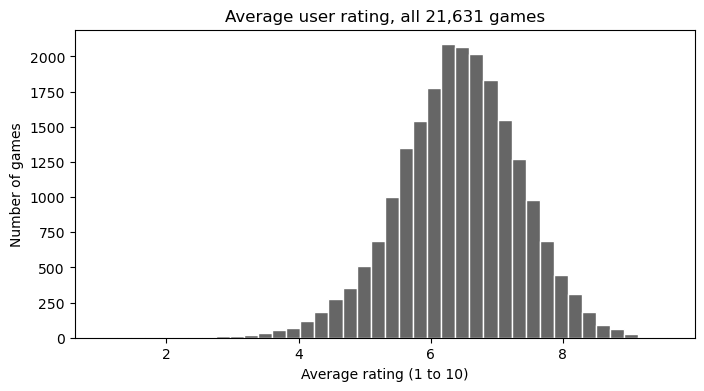

In [14]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Distribution of the target.
ax = games["average"].plot(kind="hist", bins=40, color="0.4", edgecolor="white", figsize=(8, 4))
ax.set_title("Average user rating, all 21,631 games")
ax.set_xlabel("Average rating (1 to 10)")
ax.set_ylabel("Number of games");

Mean rating 6.42, standard deviation 0.93, slight left skew; most games sit between 5.8 and 7.0.

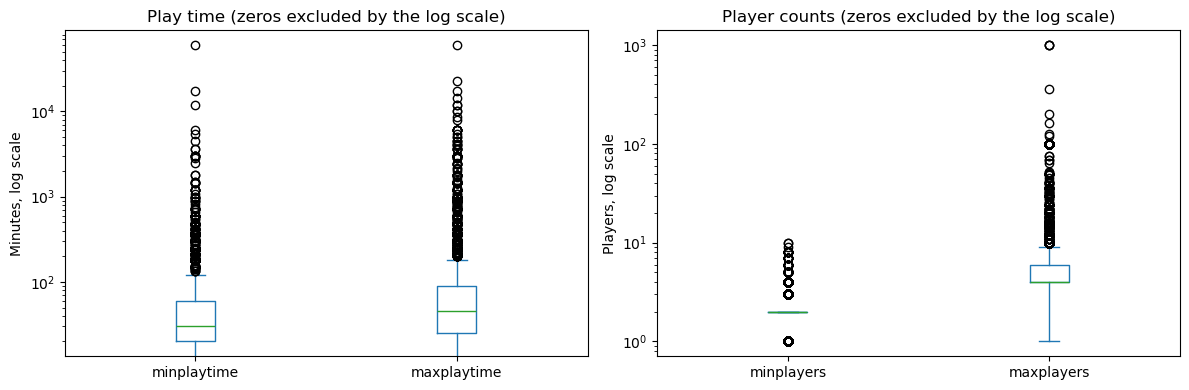

In [15]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Play time and player counts have long right tails; a log scale shows them.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
games[["minplaytime", "maxplaytime"]].plot(kind="box", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Play time (zeros excluded by the log scale)")
axes[0].set_ylabel("Minutes, log scale")
games[["minplayers", "maxplayers"]].plot(kind="box", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Player counts (zeros excluded by the log scale)")
axes[1].set_ylabel("Players, log scale")
plt.tight_layout();

The boxes are compact (median 30 to 45 minutes, 2 to 4 players) while the whiskers and outliers run to 60,000 minutes and 999 players. The extreme values are kept in the clean file; charts use log scales and models make their own cut-off decision.

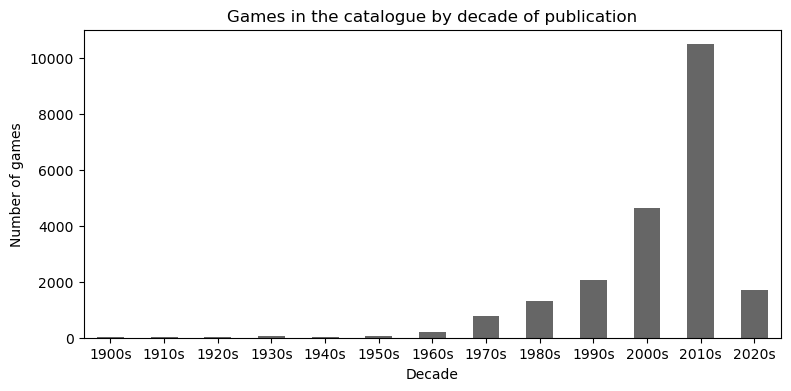

In [16]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Games per decade of publication (years at or below zero excluded).
decade = (games.loc[games["yearpublished"] > 0, "yearpublished"] // 10 * 10)
counts = decade.value_counts().sort_index()
ax = counts[counts.index >= 1900].plot(kind="bar", color="0.4", figsize=(9, 4))
ax.set_title("Games in the catalogue by decade of publication")
ax.set_xlabel("Decade")
ax.set_ylabel("Number of games")
ax.set_xticklabels([f"{int(d)}s" for d in counts[counts.index >= 1900].index], rotation=0);

The catalogue is heavily weighted to recent decades: 10,479 games from the 2010s, 4,643 from the 2000s, 2,059 from the 1990s. Any comparison across decades has to show these counts.

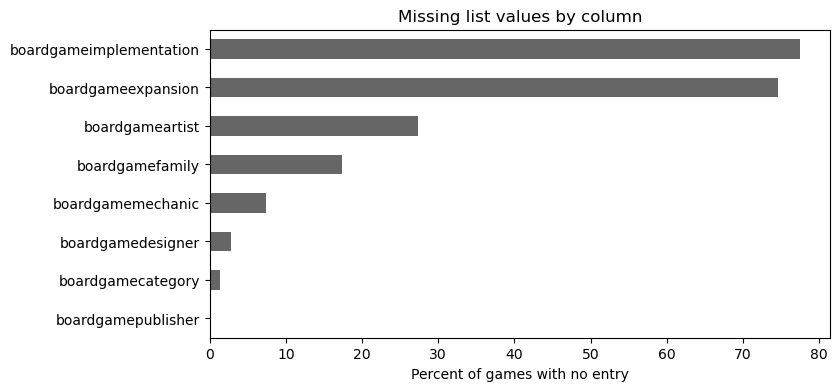

In [17]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Share of games with an empty list in each list-valued column.
list_cols = ["boardgamecategory", "boardgamemechanic", "boardgamefamily", "boardgamedesigner", "boardgameartist", "boardgamepublisher", "boardgameexpansion", "boardgameimplementation"]
ax = (games[list_cols].isna().mean() * 100).sort_values().plot(kind="barh", color="0.4", figsize=(8, 4))
ax.set_title("Missing list values by column")
ax.set_xlabel("Percent of games with no entry");

Categories are nearly complete (1.3% missing), mechanics are missing for 7.4% of games (1,590), and the expansion and implementation lists are empty for about three quarters of games because most games have none.

## 5. Cleaning rules

1. Zero in a design column becomes missing. A year at or below zero (0 is unknown; negative years are games from before year 1, such as Go) also becomes missing, since those 195 games cannot be placed in a decade comparison.
2. `playingtime` is dropped; it duplicates `maxplaytime`.
3. List columns are stored as text that looks like a Python list (`['Dice Rolling', 'Hand Management']`). They are parsed and saved as pipe-separated text (`Dice Rolling|Hand Management`), which `str.get_dummies(sep="|")` turns into 0/1 columns in one line. Counts of categories and mechanics per game are added; a count is missing where its list is missing.
4. The post-release list columns and the mixed `boardgamefamily` column are dropped.
5. A `decade` column is added for grouping.
6. Rows are not removed and extreme values are not changed. The cost of dropping rows with missing design values is reported so each analysis can decide.

In [18]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Rule 1: zero means unknown in the design columns; a year at or below zero is unknown or ancient, and is set to missing too.
clean = games.copy()
for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage"]:
    clean.loc[clean[col] == 0, col] = np.nan
clean.loc[clean["yearpublished"] <= 0, "yearpublished"] = np.nan
clean[["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage"]].isna().sum().rename("missing after rule 1").to_frame()

,missing after rule 1
yearpublished,195
minplayers,44
maxplayers,164
minplaytime,642
maxplaytime,774
minage,1301


In [19]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Rule 2: playingtime duplicates maxplaytime.
clean = clean.drop(columns=["playingtime"])

In [20]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; counts revised with Claude Code (Claude Opus 5.5), 2026-10-25; reviewed and edited by Sahil Dalal.
# Rule 3: parse the list-valued text and store it as pipe-separated text, plus counts.
import ast

def parse_list(text):
    # The file stores lists as text such as "['Economic', 'Negotiation']"; missing stays an empty list.
    if pd.isna(text):
        return []
    return list(ast.literal_eval(text))

for col in ["boardgamecategory", "boardgamemechanic", "boardgamedesigner", "boardgameartist", "boardgamepublisher"]:
    parsed = clean[col].map(parse_list)
    clean[col] = parsed.map(lambda items: "|".join(items) if len(items) > 0 else np.nan)

# A missing list means its entries are unknown, not that the game has none, so the count stays missing; "Int64" keeps whole numbers next to missing values.
clean["n_categories"] = clean["boardgamecategory"].map(lambda s: np.nan if pd.isna(s) else s.count("|") + 1).astype("Int64")
clean["n_mechanics"] = clean["boardgamemechanic"].map(lambda s: np.nan if pd.isna(s) else s.count("|") + 1).astype("Int64")
print("games with a missing count: categories", clean["n_categories"].isna().sum(), "| mechanics", clean["n_mechanics"].isna().sum())
clean[["name", "boardgamecategory", "boardgamemechanic", "n_categories", "n_mechanics"]].head()

games with a missing count: categories 283 | mechanics 1590


,name,boardgamecategory,boardgamemechanic,n_categories,n_mechanics
0,Pandemic,Medical,Action Points|Cooperative Game|Hand Management...,1,7
1,Carcassonne,City Building|Medieval|Territory Building,Area Majority / Influence|Map Addition|Tile Pl...,3,3
2,Catan,Economic|Negotiation,Dice Rolling|Hexagon Grid|Income|Modular Board...,2,9
3,7 Wonders,Ancient|Card Game|City Building|Civilization|E...,Drafting|Hand Management|Set Collection|Simult...,5,5
4,Dominion,Card Game|Medieval,"Deck, Bag, and Pool Building|Delayed Purchase|...",2,5


In [21]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Rule 4: drop the post-release list columns and the mixed family column.
clean = clean.drop(columns=["boardgameexpansion", "boardgameimplementation", "boardgamefamily"])

In [22]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Rule 5: decade of publication, for grouping (missing where the year is unknown).
clean["decade"] = clean["yearpublished"] // 10 * 10
clean["decade"].value_counts().sort_index().tail(6)

decade
1970.0      791
1980.0     1321
1990.0     2059
2000.0     4643
2010.0    10479
2020.0     1690
Name: count, dtype: int64

In [23]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Rule 6 (report only): what dropping rows with any missing design value would cost.
key = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "boardgamecategory", "boardgamemechanic"]
complete = clean[key].notna().all(axis=1)
print("rows with every key design value present:", complete.sum(), "of", len(clean), "(", round(complete.mean() * 100, 1), "% )")
clean[key].isna().sum().rename("missing").to_frame()

rows with every key design value present: 17982 of 21631 ( 83.1 % )


,missing
yearpublished,195
minplayers,44
maxplayers,164
minplaytime,642
maxplaytime,774
minage,1301
boardgamecategory,283
boardgamemechanic,1590


In [24]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Quick check that the 0/1 encoding works on the saved text format: the 15 most common mechanics.
mech = clean["boardgamemechanic"].str.get_dummies(sep="|")
print("distinct mechanics:", mech.shape[1])
mech.sum().sort_values(ascending=False).head(15).rename("games").to_frame()

distinct mechanics: 182


,games
Dice Rolling,6112
Hand Management,4421
Set Collection,2936
Variable Player Powers,2719
Hexagon Grid,2371
Simulation,2099
Card Drafting,1869
Tile Placement,1805
Modular Board,1697
Grid Movement,1635


## 6. Save the clean file

In [25]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Write data/bgg_clean.csv when running inside the repository; otherwise (for example in Colab) write next to the notebook.
import os
out_dir = "../data" if os.path.isdir("../data") else "."
out_path = os.path.join(out_dir, "bgg_clean.csv")
clean.to_csv(out_path, index=False)
print("saved", clean.shape, "to", out_path)

saved (21631, 24) to ../data/bgg_clean.csv


In [26]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# The clean table.
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21631 entries, 0 to 21630
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  21631 non-null  int64  
 1   name                21631 non-null  object 
 2   rank                21631 non-null  int64  
 3   average             21631 non-null  float64
 4   bayes_average       21631 non-null  float64
 5   users_rated         21631 non-null  int64  
 6   yearpublished       21436 non-null  float64
 7   minplayers          21587 non-null  float64
 8   maxplayers          21467 non-null  float64
 9   minplaytime         20989 non-null  float64
 10  maxplaytime         20857 non-null  float64
 11  minage              20330 non-null  float64
 12  boardgamecategory   21348 non-null  object 
 13  boardgamemechanic   20041 non-null  object 
 14  boardgamedesigner   21035 non-null  object 
 15  boardgameartist     15724 non-null  object 
 16  boar

## 7. What the clean file contains

| Column | Meaning |
| --- | --- |
| `id`, `name` | Game identifier and name; not model inputs |
| `average` | Mean user rating, the predictive target |
| `bayes_average`, `rank`, `users_rated`, `owned`, `trading`, `wanting`, `wishing` | Post-release community outcomes; kept for description, never used as model inputs |
| `yearpublished`, `decade` | Year of publication (missing where unknown) and its decade |
| `minplayers`, `maxplayers` | Player count range (missing where unknown) |
| `minplaytime`, `maxplaytime` | Play time range in minutes (missing where unknown) |
| `minage` | Publisher's minimum age (missing where unknown) |
| `boardgamecategory`, `boardgamemechanic` | Pipe-separated lists; `str.get_dummies(sep="|")` makes 0/1 columns |
| `n_categories`, `n_mechanics` | Number of entries in each list (missing where the list is missing) |
| `boardgamedesigner`, `boardgameartist`, `boardgamepublisher` | Pipe-separated lists of names |